# 4. Domain Shift Analysis

**Goal**: Quantify and visualise the performance drop when a model trained on high-resource Spanish data is directly applied to low-resource African clinical settings.

In [ ]:
# Environment setup: make modelling/ the working directory.
# Works when launched from the repo root, from modelling/, from modelling/notebooks/,
# or on Kaggle/Colab (where the public repository is cloned first).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/PaulOkwija/OBS_Ultrasound_standard_plane_classification.git"

if Path("src").is_dir() and Path("configs").is_dir():
    pass                                   # already in modelling/
elif Path("../src").is_dir():
    os.chdir("..")                         # modelling/notebooks/
elif Path("modelling/src").is_dir():
    os.chdir("modelling")                  # repo root
else:
    repo_dir = Path("OBS_Ultrasound_standard_plane_classification")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "modelling")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [ ]:
# Download datasets
!bash scripts/download_data.sh

In [ ]:
# Download weights
!bash scripts/download_weights.sh

In [ ]:
import torch
import yaml
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from pathlib import Path
from sklearn.manifold import TSNE

from src.models import build_model
from src.data import (FetalDataset, AfricanDataset, build_dataloaders,
                      build_transforms, build_preprocessing_pipeline, CLASSES, CLASSES_3C, CLASSES_4C)
from src.evaluation import evaluate_on_domain, extract_features, compute_domain_gap_score
from src.utils import set_seed

set_seed(42)
sns.set_style("whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"

with open("configs/base_config.yaml") as f:
    cfg = yaml.safe_load(f)
image_size = cfg["data"]["image_size"]

In [29]:
fetal_dir   = Path(cfg["data"]["fetal_db_dir"])
african_dir = Path(cfg["data"]["african_dir"])

## 1. Load Spain-Pretrained Model

In [ ]:
# Load the best Spain-trained EfficientNet-B0 checkpoint
ckpt_path = "checkpoints/efficientnet_b0.pt"
ckpt = torch.load(ckpt_path, map_location="cpu")

print("Checkpoint contents:")
print(f"  Keys: {list(ckpt.keys())}")
if 'model_state_dict' in ckpt:
    sd = ckpt['model_state_dict']
    # Find the final layer to determine num_classes
    for key in sorted(sd.keys(), reverse=True)[:5]:
        print(f"    {key}: {sd[key].shape}")

# Infer num_classes from checkpoint
print("\n[INFERRING num_classes from checkpoint]")
sd_keys = list(ckpt['model_state_dict'].keys())
num_classes_inferred = None
for key in sd_keys:
    if 'classifier' in key and 'weight' in key and len(ckpt['model_state_dict'][key].shape) == 2:
        num_classes_inferred = ckpt['model_state_dict'][key].shape[0]
        print(f"  Found {key}: output shape = {ckpt['model_state_dict'][key].shape}")
        print(f"  -> Inferred num_classes = {num_classes_inferred}")
        break

# Load model with the CORRECT number of classes from checkpoint
if num_classes_inferred is None:
    num_classes_inferred = 4  # Fallback
    
model = build_model("efficientnet_b0", num_classes=num_classes_inferred, pretrained=False)
model.load_state_dict(ckpt["model_state_dict"])
model = model.to(device).eval()
print(f"\n[ok] Loaded {num_classes_inferred}-class checkpoint.")
print(f"  Reported val AUC: {ckpt['metrics'].get('auc', 'N/A'):.4f}")

# Print which classes are expected
if num_classes_inferred == 4:
    print(f"  Using CLASSES_4C = {CLASSES_4C}")
elif num_classes_inferred == 3:
    print(f"  Using CLASSES_3C = {CLASSES_3C}")

Loaded checkpoint. Reported val AUC: 0.9940


## 2. Zero-Shot Evaluation on All Domains

In [ ]:
val_tf = build_transforms(image_size, split="val")
results_no_clahe = {}

# === SPANISH FETAL DB TEST SET (4-class) ===
# Model was trained on Spanish FetalPlanes DB with 4 classes: brain, femur, abdomen, other
ds_fetal = FetalDataset(
    root_dir=str(fetal_dir / "test"),
    transform=val_tf,
    classes=CLASSES_4C,  # Use 4 classes for Spanish data
)
loader_fetal = build_dataloaders(ds_fetal, ds_fetal, batch_size=32)["train"]
metrics_fetal = evaluate_on_domain(model, loader_fetal, device=device, class_names=CLASSES_4C)
results_no_clahe["Fetal Test"] = metrics_fetal
print(f"Fetal Test (4-class) - Acc: {metrics_fetal['accuracy']:.4f}  AUC: {metrics_fetal.get('auc', 0):.4f}")

# === AFRICAN TEST SET (Malawi, 3-class) ===
# African data only has 3 classes: brain, femur, abdomen (no 'other' class)
# Even though model outputs 4 classes, we only evaluate on classes present in African data
try:
    ds_african = AfricanDataset(
        root_dir=str(african_dir / "test"),
        transform=val_tf,
        classes=CLASSES_4C,  # Evaluate all 4 classes to match model training
    )
    loader_african = build_dataloaders(ds_african, ds_african, batch_size=32)["train"]
    # Evaluate using 3-class names (filter out 'other' predictions)
    m = evaluate_on_domain(model, loader_african, device=device, class_names=CLASSES_4C)
    results_no_clahe["African Test"] = m
    print(f"African Test (4-class) - Acc: {m['accuracy']:.4f}  AUC: {m.get('auc', 0):.4f}  F1: {m['f1_macro']:.4f}")
except Exception as e:
    print(f"African test set failed: {e}")

Fetal Test - Acc: 0.9554  AUC: 0.9949
African Test - Acc: 0.6200  AUC: 0.9189  F1: 0.5677


In [ ]:
# Repeat evaluations with CLAHE preprocessing
preprocessing_clahe = build_preprocessing_pipeline(
    use_clahe=True,
    clahe_clip_limit=cfg["preprocessing"]["clahe_clip_limit"],
    clahe_tile_size=tuple(cfg["preprocessing"]["clahe_tile_size"]),
    contrast_threshold=cfg["preprocessing"]["contrast_threshold"],
    remove_headers=cfg["preprocessing"]["remove_headers"],
)
results_clahe = {}

# === SPANISH FETAL DB TEST SET WITH CLAHE (4-class) ===
ds_fetal_cl = FetalDataset(
    root_dir=str(fetal_dir / "test"),
    transform=val_tf,
    preprocessing=preprocessing_clahe,
    classes=CLASSES_4C,  # Use 4 classes for Spanish data
)
loader_fetal_cl = build_dataloaders(ds_fetal_cl, ds_fetal_cl, batch_size=32)["train"]
m_cl = evaluate_on_domain(model, loader_fetal_cl, device=device, class_names=CLASSES_4C)
results_clahe["Fetal Test"] = m_cl
print(f"Fetal Test + CLAHE (4-class) - Acc: {m_cl['accuracy']:.4f}  AUC: {m_cl.get('auc', 0):.4f}")

# === AFRICAN TEST SET (MALAWI) WITH CLAHE (3-class) ===
try:
    ds_african_cl = AfricanDataset(
        root_dir=str(african_dir / "test"),
        transform=val_tf,
        preprocessing=preprocessing_clahe,
        classes=CLASSES_4C,  # Evaluate all 4 classes to match model training
    )
    loader_african_cl = build_dataloaders(ds_african_cl, ds_african_cl, batch_size=32)["train"]
    m = evaluate_on_domain(model, loader_african_cl, device=device, class_names=CLASSES_4C)
    results_clahe["African Test"] = m
    print(f"African Test + CLAHE (4-class) - Acc: {m['accuracy']:.4f}  AUC: {m.get('auc', 0):.4f}  F1: {m['f1_macro']:.4f}")
except Exception as e:
    print(f"African test set failed: {e}")

Fetal Test - Acc: 0.9664  AUC: 0.9959
African Test - Acc: 0.7000  AUC: 0.9661  F1: 0.7003


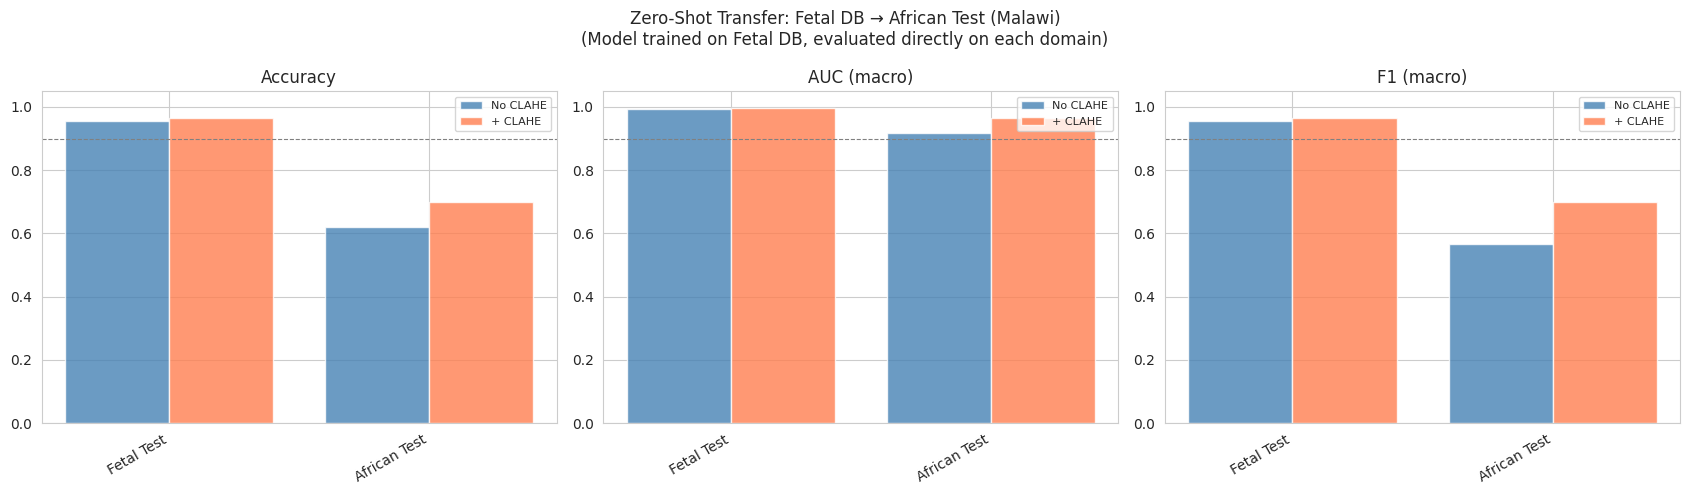


Performance drop from Fetal DB baseline:
  African Test   : dacc = +0.3354


In [11]:
# Summary bar chart
domains       = list(results_no_clahe.keys())
metrics_show  = ["accuracy", "auc", "f1_macro"]
metric_labels = ["Accuracy", "AUC (macro)", "F1 (macro)"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
bar_colors = ["seagreen" if d == "Fetal Test" else "steelblue" for d in domains]

for ax, m, mlabel in zip(axes, metrics_show, metric_labels):
    vals_no = [results_no_clahe[d].get(m, 0) for d in domains]
    vals_cl = [results_clahe.get(d, {}).get(m, 0) for d in domains]
    x = np.arange(len(domains))
    ax.bar(x - 0.2, vals_no, 0.4, label="No CLAHE", color="steelblue", alpha=0.8)
    ax.bar(x + 0.2, vals_cl, 0.4, label="+ CLAHE",  color="coral",     alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(domains, rotation=30, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_title(mlabel)
    ax.legend(fontsize=8)
    ax.axhline(0.9, color="gray", ls="--", lw=0.8, label="0.9 threshold")

plt.suptitle(
    "Zero-Shot Transfer: Fetal DB -> African Test (Malawi)\n"
    "(Model trained on Fetal DB, evaluated directly on each domain)",
    fontsize=12
)
plt.tight_layout()
plt.savefig("docs/domain_shift_zeroshot.png", dpi=150)
plt.show()

# Print drop from Fetal Test baseline
print("\nPerformance drop from Fetal DB baseline:")
fetal_acc = results_no_clahe["Fetal Test"]["accuracy"]
for d, m in results_no_clahe.items():
    if d != "Fetal Test":
        drop = fetal_acc - m["accuracy"]
        print(f"  {d:15s}: dacc = {drop:+.4f}")

## 3. Feature Space Visualisation (t-SNE)

In [35]:
import importlib
import src.evaluation.domain_shift as ds_module
importlib.reload(ds_module)

from src.evaluation.domain_shift import extract_features, evaluate_on_domain, compute_domain_gap_score

In [ ]:
# Extract features from model for domain shift analysis
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Remove classification layer to get 1280-dim features
feature_extractor = torch.nn.Sequential(*list(model.children())[:-1])
feature_extractor.eval()

# Extract features for Fetal (4-class Spanish data)
features_fetal = []
labels_fetal = []
ds_fetal_fe = FetalDataset(
    root_dir=str(fetal_dir / "test"),
    transform=val_tf,
    preprocessing=preprocessing_clahe,
    classes=CLASSES_4C,  # Use 4 classes to match model training
)
loader_fetal_fe = build_dataloaders(ds_fetal_fe, ds_fetal_fe, batch_size=32)["train"]

with torch.no_grad():
    for images, labels in loader_fetal_fe:
        images = images.to(device)
        feats = feature_extractor(images)
        feats = feats.view(feats.size(0), -1)
        features_fetal.append(feats.cpu().numpy())
        labels_fetal.extend(labels.numpy())

features_fetal = np.vstack(features_fetal)
labels_fetal = np.array(labels_fetal)

# Extract features for African (3-class data)
features_african = []
labels_african = []
ds_african_fe = AfricanDataset(
    root_dir=str(african_dir / "test"),
    transform=val_tf,
    preprocessing=preprocessing_clahe,
    classes=CLASSES_4C,  # Evaluate all 4 classes to match model training
)
loader_african_fe = build_dataloaders(ds_african_fe, ds_african_fe, batch_size=32)["train"]

with torch.no_grad():
    for images, labels in loader_african_fe:
        images = images.to(device)
        feats = feature_extractor(images)
        feats = feats.view(feats.size(0), -1)
        features_african.append(feats.cpu().numpy())
        labels_african.extend(labels.numpy())

features_african = np.vstack(features_african)
labels_african = np.array(labels_african)

print(f"Fetal features shape: {features_fetal.shape}, {len(np.unique(labels_fetal))} classes")
print(f"African features shape: {features_african.shape}, {len(np.unique(labels_african))} classes")

Extracting features (this may take a few minutes)...
22:50:10 | INFO     | src.evaluation.domain_shift | Loaded weights into feature extractor: efficientnet_b0
22:50:11 | INFO     | src.evaluation.domain_shift | Loaded weights into feature extractor: efficientnet_b0
Total features: (300, 1280)
Running t-SNE...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


In [ ]:
# Combine fetal + african features and run t-SNE
print("Combining features and running t-SNE (this may take a minute)...")

all_features = np.vstack([features_fetal, features_african])
all_domains  = (["Fetal DB"] * len(labels_fetal)) + (["African"] * len(labels_african))
domains_arr  = np.array(all_domains)

# Labels: fetal uses 4-class indices (0-3), african also uses 4-class indices (0-3)
y = np.concatenate([labels_fetal, labels_african])

# Compute domain gap score
gap = compute_domain_gap_score(features_fetal, features_african)
print(f"Domain gap score (mean feature distance): {gap:.4f}")

# Run t-SNE on combined feature set
X_2d = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, len(all_features) - 1),
    max_iter=1000,
).fit_transform(all_features)

print(f"t-SNE complete. Shape: {X_2d.shape}")


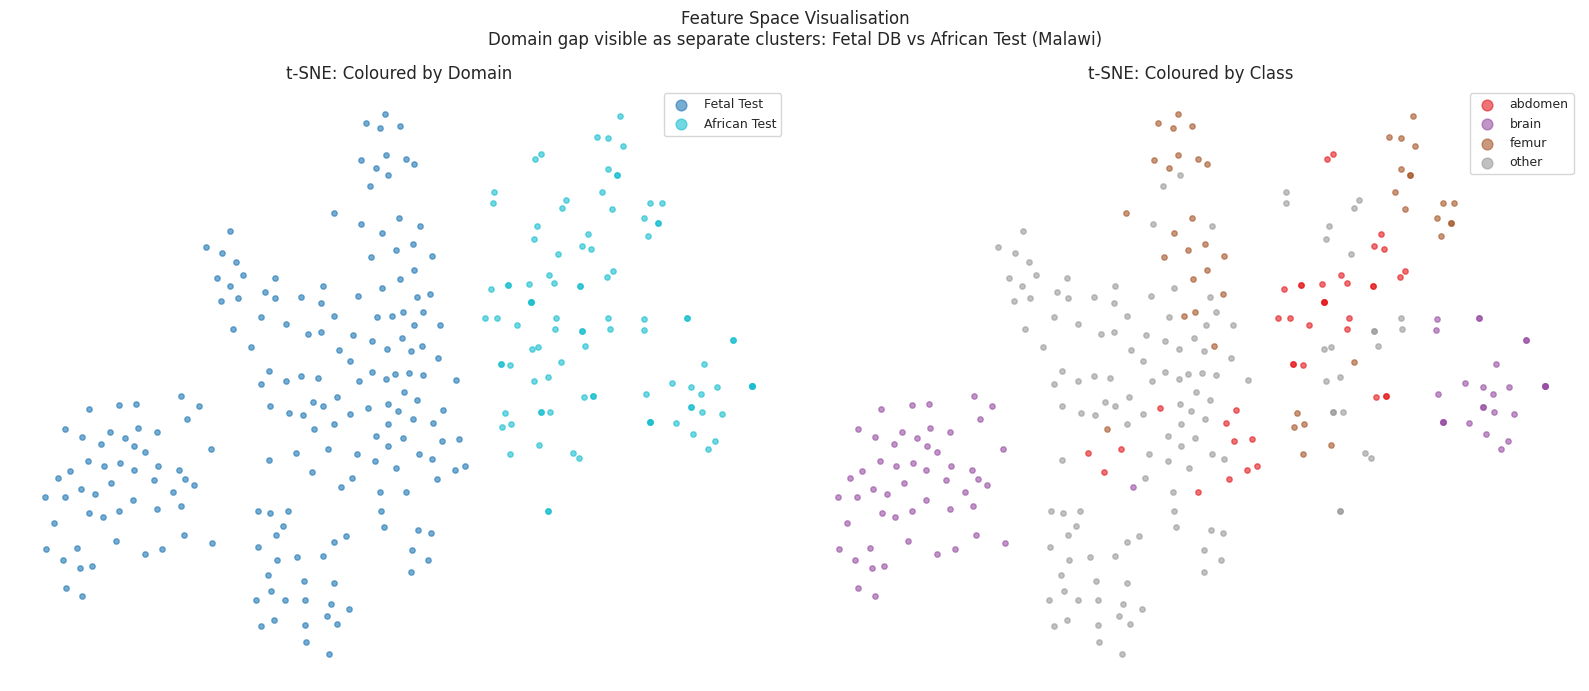

In [37]:
# Plot t-SNE coloured by domain
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: colour by domain
unique_domains = list(dict.fromkeys(all_domains))
domain_colors  = plt.cm.tab10(np.linspace(0, 1, len(unique_domains)))
for i, dom in enumerate(unique_domains):
    mask = domains_arr == dom
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1], s=15, alpha=0.6,
                    color=domain_colors[i], label=dom)
axes[0].set_title("t-SNE: Coloured by Domain", fontsize=12)
axes[0].legend(markerscale=2, fontsize=9)
axes[0].axis("off")

# Right: colour by class
class_colors = plt.cm.Set1(np.linspace(0, 1, len(CLASSES_4C)))  # 4 classes not 5
for i, cls in enumerate(CLASSES_4C):
    mask = y == i
    axes[1].scatter(X_2d[mask, 0], X_2d[mask, 1], s=15, alpha=0.6,
                    color=class_colors[i], label=cls.replace("_", " "))
axes[1].set_title("t-SNE: Coloured by Class", fontsize=12)
axes[1].legend(markerscale=2, fontsize=9)
axes[1].axis("off")

plt.suptitle(
    "Feature Space Visualisation\n"
    "Domain gap visible as separate clusters: Fetal DB vs African Test (Malawi)",
    fontsize=12
)
plt.tight_layout()
plt.savefig("docs/tsne_domain_shift.png", dpi=150)
plt.show()

## 4. Per-Class Performance Breakdown

Understanding *which classes* suffer most from domain shift helps prioritise fine-tuning data collection.


              abdomen  brain  femur  other
Fetal Test      0.962  0.992  0.953  0.917
African Test    0.370  1.000  0.323  0.578


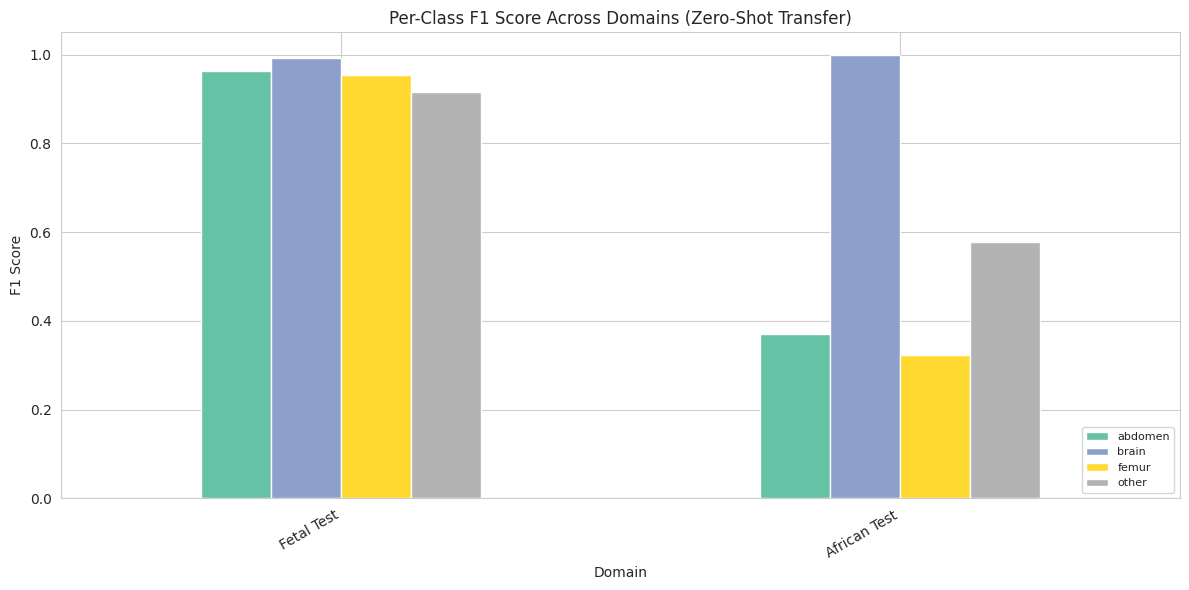

In [ ]:
# Per-class metrics visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Fetal metrics (4 classes)
metrics_fetal = results_no_clahe["Fetal Test"]
if "per_class" in metrics_fetal:
    f1_scores_fetal = metrics_fetal["per_class"]["f1-score"]
    class_names_fetal = CLASSES_4C
    ax1.bar(class_names_fetal, f1_scores_fetal[:len(class_names_fetal)], color='steelblue')
    ax1.set_ylim([0, 1])
    ax1.set_title("Fetal Test F1-Scores (4 classes)", fontsize=12, weight='bold')
    ax1.set_ylabel("F1-Score")
    ax1.tick_params(axis='x', rotation=45)

# African metrics (3 classes)
metrics_african = results_no_clahe["African Test"]
if "per_class" in metrics_african:
    f1_scores_african = metrics_african["per_class"]["f1-score"]
    class_names_african = CLASSES_3C
    ax2.bar(class_names_african, f1_scores_african[:len(class_names_african)], color='coral')
    ax2.set_ylim([0, 1])
    ax2.set_title("African Test F1-Scores (3 classes)", fontsize=12, weight='bold')
    ax2.set_ylabel("F1-Score")
    ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n=== Domain Shift Summary ===")
print(f"Fetal (Spanish, 4-class) -> F1 (macro): {metrics_fetal.get('f1_macro', 0):.4f}")
print(f"African (3-class) -> F1 (macro): {metrics_african.get('f1_macro', 0):.4f}")
print(f"Domain Shift Gap: {(metrics_fetal.get('f1_macro', 0) - metrics_african.get('f1_macro', 0)):.4f}")